# Discretization and a benchmark solver

How can we tell whether a better-looking solution is actually becoming more accurate?

Fall 2024.


## Predict
This original periodic sine benchmark uses exact cell averages. Predict the error ratio for first- and second-order convergence. State what must remain fixed in a time-step experiment.

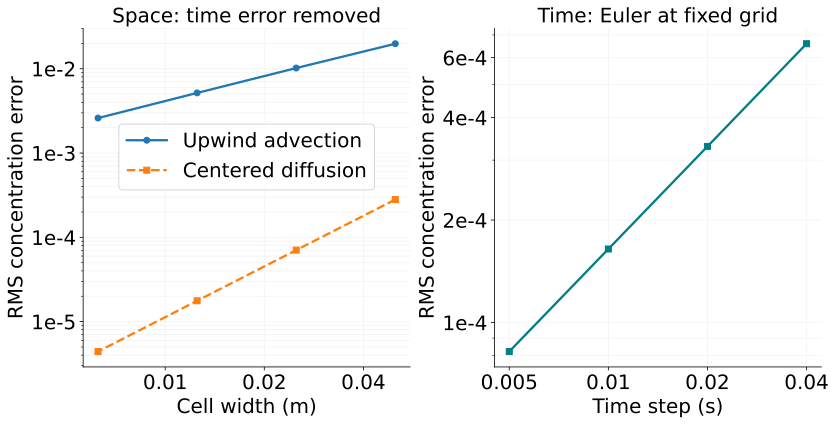

{'Upwind advection': {'errors': [0.019808116194183514,
   0.010197218745354597,
   0.005167920498185098,
   0.0026007203498155966],
  'orders': [0.9579159665443717, 0.9805199346717319, 0.9906725986444771]},
 'Centered diffusion': {'errors': [0.0002808429902895573,
   7.055901514515195e-05,
   1.766157065497422e-05,
   4.416757002134216e-06],
  'orders': [1.9928614651960945, 1.9982167755591724, 1.9995542819539025]}}

In [1]:
import numpy as np
from demo import run, exact_mode, euler_mode, rms
from IPython.display import SVG, display
report = run()
display(SVG(filename="separate-errors.svg"))
report["spatial"]

## Implement the guided diagnostic
Translate the log-ratio definition into a loop or vector operation. The runnable starter is supplied for comparison; replace its body with your own equivalent implementation. The simple power-law check is a guided example.

In [2]:
def observed_order(errors):
    errors = np.asarray(errors, dtype=float)
    if errors.ndim != 1 or len(errors)<2 or np.any(errors<=0) or not np.isfinite(errors).all():
        raise ValueError("Use at least two positive finite errors")
    return np.log2(errors[:-1]/errors[1:])
np.testing.assert_allclose(observed_order([.04,.01,.0025]), [2,2])
print(observed_order(report["temporal_errors"]))

[1.00229426 1.00119197 1.00060712]


## Run and modify
Hold the 64-cell spatial model fixed, change only the time step, and compare to its exact semi-discrete evolution. Try another velocity sign and predict which error magnitude should be similar. Explain why this reference does not measure spatial error.

[0.0006593433537408259, 0.0003291478287807114, 0.00016443799804256008] [1.00229426 1.00119197]


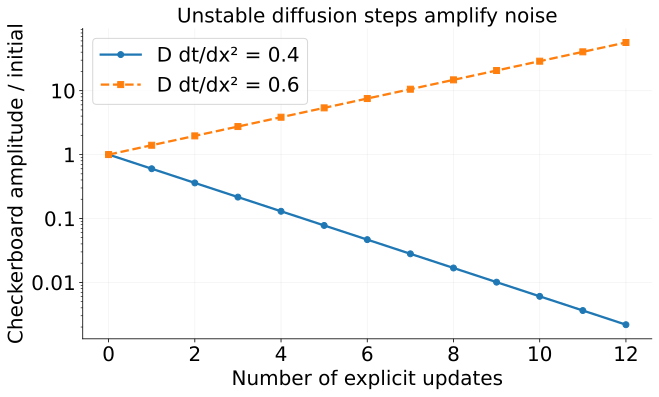

In [3]:
_, reference = exact_mode(64, -.1, .001, end=.4, semidiscrete=True)
errors=[]
for dt in [.04,.02,.01]:
    _, c, actual_dt, _, _ = euler_mode(64, -.1, .001, end=.4, dt=dt)
    errors.append(rms(c, reference))
print(errors, observed_order(errors))
display(SVG(filename="stability-mode.svg"))

## Interpret
State one verified numerical property and one untested feature. Explain how a growing checkerboard can preserve the same total amount.